### Activity 6 Supervised Classification

In [126]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [127]:
X_apps = [[2.5, 1], [8.0, 0], [3.0, 1], [12.0, 0], [5.0, 1], [7.0, 0], [4.0, 1], [10.0, 0], [6.0, 1], [9.0, 0], [11.0, 1], [1.0, 0], [2.0, 1], [3.5, 0], [4.5, 1], [5.5, 0]]
y_decision = [1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0]

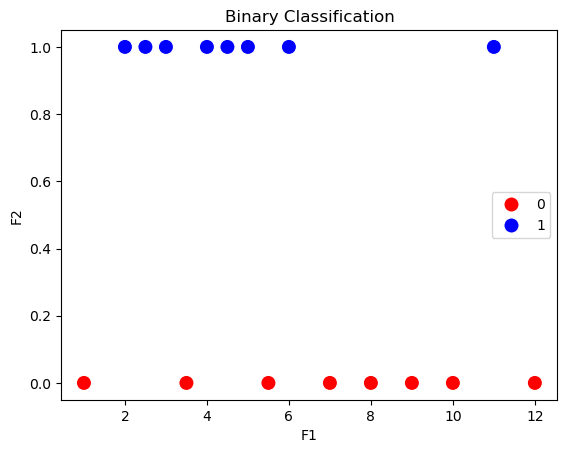

In [128]:
X = np.array(X_apps)

sns.scatterplot(
    x=X[:, 0],
    y=X[:, 1],
    hue=y_decision,
    palette={0: "red", 1: "blue"},
    s=120
)

plt.xlabel("F1")
plt.ylabel("F2")
plt.title("Binary Classification")
plt.show()

In [129]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000,C=100)
model.fit(X_apps, y_decision)

print(model.coef_)
print(model.intercept_)

[[-0.11180888  8.85268425]]
[-3.77985496]


In [130]:
model

,penalty,'l2'
,dual,False
,tol,0.0001
,C,100
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [131]:
new_applicant = [[3.5, 0]]
result = model.predict(new_applicant)

status = "Approved (1)" if result[0] == 1 else "Rejected (0)"
print(f"Application Result: {status}")

Application Result: Rejected (0)


<Axes: >

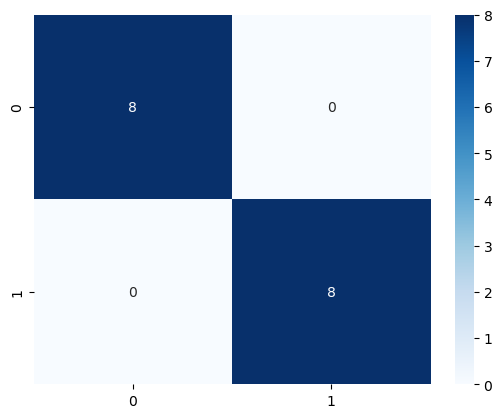

In [132]:

from sklearn.metrics import confusion_matrix

sns.heatmap(confusion_matrix(y_decision, model.predict(X_apps)), annot=True, fmt='d', cmap='Blues')

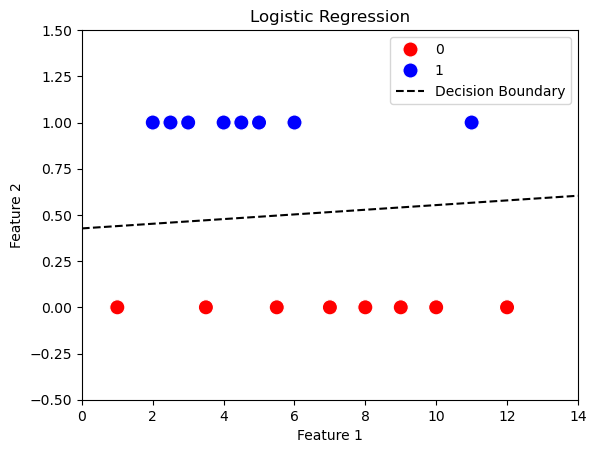

In [133]:
# Extract weights and bias
w1, w2 = model.coef_[0]
b = model.intercept_[0]

# Generate decision boundary
x1 = np.linspace(0, 14, 100)
x2 = -(w1 * x1 + b) / w2

# Plot data points
sns.scatterplot(
    x=[i[0] for i in X_apps],
    y=[i[1] for i in X_apps],
    hue=y_decision,
    palette={0: "red", 1: "blue"},
    s=120
)

# Plot decision boundary
plt.plot(x1, x2, linestyle="--", color="black",
         label="Decision Boundary")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic Regression")
# plt.yticks([0,1])
plt.xlim(0, 14)
plt.ylim(-0.5, 1.5)
plt.legend()
plt.show()

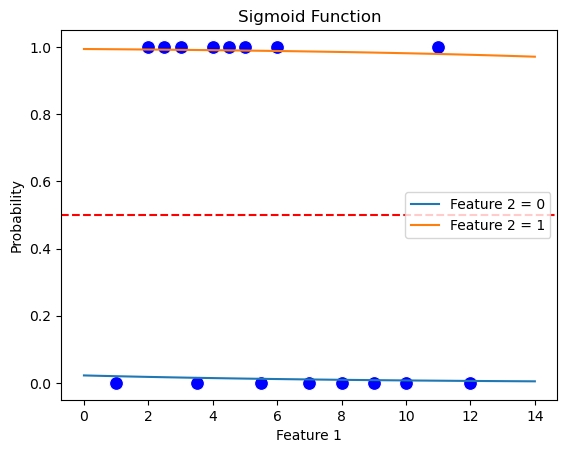

In [134]:
x1 = np.linspace(0, 14, 100)

for x2 in [0, 1]:

    z = w1 * x1 + w2 * x2 + b

    # Sigmoid function
    probability = 1 / (1 + np.exp(-z))

    plt.plot(x1, probability, label=f"Feature 2 = {x2}")

sns.scatterplot(
    x=[i[0] for i in X_apps],
    y=y_decision,
    color="blue",
    s=100
)

plt.axhline(0.5, color="red", linestyle="--")

plt.xlabel("Feature 1")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.legend()
plt.show()